<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Count requests without inventing identities

**What does a browser breakdown actually count?** We will parse synthetic HTTP
User-Agent strings through the real VGI worker, join the results back to individual
requests, and compare request counts with distinct supplied strings. Missing headers,
empty strings and unrecognized clients remain visible before and after a bot-signature
filter.

These are authored requests, not logs from real people. User-Agent values are supplied
by clients and can be copied or changed. A parsed family is not a verified device,
a distinct string is not a visitor, and absence of a bot signature does not establish
human traffic. The worker performs local text parsing only.

## Choose whether to exclude identified bot signatures

`EXCLUDE_IDENTIFIED_BOTS=True` removes rows whose parsed flag is explicitly true.
The experiment changes this to `False`. Missing flags and unrecognized clients remain
in the audit and selected population. Restart the kernel and run all after changing
this boolean parameter.

In [1]:
EXCLUDE_IDENTIFIED_BOTS = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(EXCLUDE_IDENTIFIED_BOTS) is not bool:
    raise ValueError("EXCLUDE_IDENTIFIED_BOTS must be True or False.")
quality = browser_counts = selection = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-useragent/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-useragent/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-useragent/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-useragent/notebooks/pyproject.toml.

## Attach the native release

The literal `github-auto` location fetches the v0.4.0 binary for this platform,
verifies its release checksum, and caches it. No Rust installation or local worker
build is needed. The uap-core regular-expression data is embedded in the release,
so parsing needs neither a database file nor a network request.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'useragent' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-useragent@v0.4.0');

,Success


## Expand authored header patterns into request rows

The repetition count creates one row per synthetic request. Two Chrome version
strings intentionally share a browser family. The curl client and a custom unknown
client show why a false bot flag cannot establish a human. NULL and the empty string
are separate inputs. IDs identify fixture requests, not users or sessions.

In [4]:
%%sql
CREATE TABLE header_patterns AS
SELECT * FROM (VALUES
 ('C120','Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',4),
 ('C121','Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/121.0.0.0 Safari/537.36',2),
 ('IOS','Mozilla/5.0 (iPhone; CPU iPhone OS 17_0 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.0 Mobile/15E148 Safari/604.1',3),
 ('FF','Mozilla/5.0 (X11; Linux x86_64; rv:120.0) Gecko/20100101 Firefox/120.0',1),
 ('CURL','curl/8.5.0',2),
 ('GOOG','Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html)',2),
 ('BING','Mozilla/5.0 (compatible; bingbot/2.0; +http://www.bing.com/bingbot.htm)',1),
 ('UNKNOWN','ExampleClient/0.1 not-a-known-browser',1),
 ('EMPTY','',1),
 ('MISSING',NULL,1)
) t(pattern_id,ua,repetitions);
CREATE TABLE requests AS
SELECT row_number() OVER(ORDER BY pattern_id,copy_no) AS request_id,pattern_id,ua
FROM header_patterns CROSS JOIN LATERAL range(1,repetitions+1) t(copy_no);
SELECT pattern_id,repetitions,ua FROM header_patterns ORDER BY pattern_id;

,pattern_id,repetitions,ua
0,BING,1,Mozilla/5.0 (compatible; bingbot/2.0; +http://...
1,C120,4,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
2,C121,2,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...
3,CURL,2,curl/8.5.0
4,EMPTY,1,
5,FF,1,Mozilla/5.0 (X11; Linux x86_64; rv:120.0) Geck...
6,GOOG,2,Mozilla/5.0 (compatible; Googlebot/2.1; +http:...
7,IOS,3,Mozilla/5.0 (iPhone; CPU iPhone OS 17_0 like M...
8,MISSING,1,None
9,UNKNOWN,1,ExampleClient/0.1 not-a-known-browser


## Parse each distinct string once and join it back safely

`ua_parse` returns a struct with browser, OS, device, version, brand and bot fields.
Materialize the distinct-string dictionary, then reuse it. The join uses
`IS NOT DISTINCT FROM` so the NULL header matches its NULL dictionary key instead
of disappearing. Equal strings share a parse; they do not establish equal identities.

The parser maps unknown `Other` families to NULL. Empty/unrecognized strings have
a non-NULL struct with unknown fields and `is_bot=false`; a SQL NULL input returns
a NULL struct. A missing device model is not evidence of a desktop device. For
identified spiders, the worker deliberately suppresses device and brand fields.

In [5]:
%%sql
CREATE TABLE parsed_headers AS
SELECT ua,useragent.main.ua_parse(ua) AS parsed
FROM (SELECT DISTINCT ua FROM requests);
CREATE TABLE parsed_requests AS
SELECT r.*,p.parsed,
 p.parsed.browser AS browser,p.parsed.browser_version AS browser_version,
 p.parsed.os AS os,p.parsed.os_version AS os_version,
 p.parsed.device AS device,p.parsed.brand AS brand,p.parsed.is_bot AS is_bot
FROM requests r JOIN parsed_headers p ON r.ua IS NOT DISTINCT FROM p.ua;
SELECT pattern_id,count(*) AS requests,
 first(browser) AS browser,first(browser_version) AS browser_version,
 first(os) AS os,first(device) AS device,first(brand) AS brand,first(is_bot) AS is_bot
FROM parsed_requests GROUP BY pattern_id ORDER BY pattern_id;

,pattern_id,requests,browser,browser_version,os,device,brand,is_bot
0,BING,1,bingbot,2.0,None,None,None,True
1,C120,4,Chrome,120.0.0,Windows,None,None,False
2,C121,2,Chrome,121.0.0,Windows,None,None,False
3,CURL,2,curl,8.5.0,None,None,None,False
4,EMPTY,1,None,None,None,None,None,False
5,FF,1,Firefox,120.0,Linux,None,None,False
6,GOOG,2,Googlebot,2.1,None,None,None,True
7,IOS,3,Mobile Safari,17.0,iOS,iPhone,Apple,False
8,MISSING,1,None,None,None,None,None,<NA>
9,UNKNOWN,1,None,None,None,None,None,False


## Keep header availability distinct from recognition

Classify the full request population before selecting a subset. A missing header,
an empty header and a supplied but unrecognized string are different states even
though all lack a recognized browser family. Bot identification is the embedded
parser's `Spider` signature, not a verified claim about the sender.

These small fixture strings are checked to be inside the worker's 64 KiB matching
bound. The example makes no completeness claim for oversized or future user agents.

In [6]:
%%sql
CREATE TABLE request_audit AS
SELECT *,CASE
 WHEN ua IS NULL THEN 'Missing header'
 WHEN ua='' THEN 'Empty header'
 WHEN is_bot THEN 'Identified bot signature'
 WHEN browser IS NULL THEN 'Unrecognized client'
 ELSE 'Recognized client; no bot signature' END AS input_state,
 CASE WHEN browser IS NOT NULL THEN browser
      WHEN ua IS NULL THEN '[missing header]'
      WHEN ua='' THEN '[empty header]'
      ELSE '[unrecognized client]' END AS browser_bucket
FROM parsed_requests;
SELECT input_state,count(*) AS requests FROM request_audit GROUP BY input_state ORDER BY requests DESC;

,input_state,requests
0,Recognized client; no bot signature,12
1,Identified bot signature,3
2,Empty header,1
3,Unrecognized client,1
4,Missing header,1


In [7]:
%%sql quality <<
SELECT input_state,count(*) AS requests FROM request_audit
GROUP BY input_state ORDER BY requests DESC,input_state;

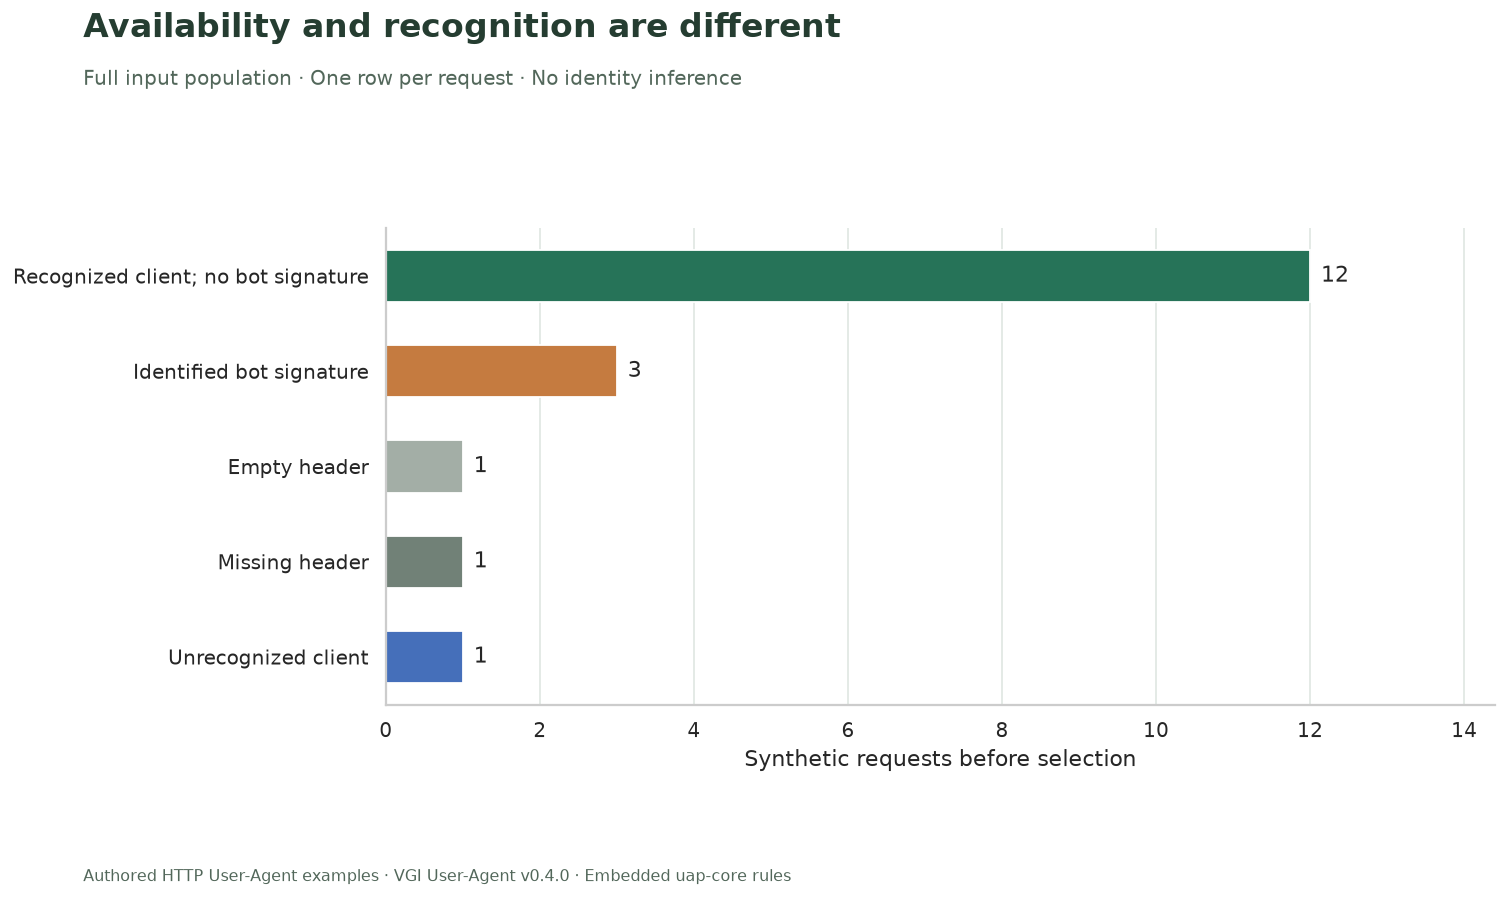

The audit retains **18 requests** across all header states. The recognized curl client has no Spider signature, and the unknown client also has a false flag. Neither observation establishes a person behind the request. This chart is independent of the selection parameter.

In [8]:
colors = {
    "Recognized client; no bot signature": "#267358",
    "Identified bot signature": "#c57b40",
    "Unrecognized client": "#456fba",
    "Empty header": "#a3aea6",
    "Missing header": "#718177",
}
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    quality.input_state,
    quality.requests,
    color=[colors[x] for x in quality.input_state],
    height=0.55,
)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, int(quality.requests.max()) * 1.2)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Synthetic requests before selection")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Availability and recognition are different",
    "Full input population · One row per request · No identity inference",
    "01_header_states.png",
    bottom=0.12,
)
prose(
    f"The audit retains **{int(quality.requests.sum())} requests** across all header states. "
    "The recognized curl client has no Spider signature, and the unknown client also has a false flag. "
    "Neither observation establishes a person behind the request. This chart is independent of the selection parameter."
)

## Remove only explicitly identified bots

`WHERE NOT is_bot` also drops SQL NULL because WHERE retains only true conditions.
The explicit `IS DISTINCT FROM true` below keeps unknown flags while excluding true
ones. We expose the naive filter's count alongside the audited selection so the
missing-header effect is visible. No unknown flag is rewritten in the stored data.

In [9]:
%%sql
CREATE TABLE selected_requests AS
SELECT * FROM request_audit
WHERE NOT {{ EXCLUDE_IDENTIFIED_BOTS }} OR is_bot IS DISTINCT FROM true;
CREATE TABLE selection_audit AS
SELECT (SELECT count(*) FROM request_audit) AS original_requests,
 (SELECT count(*) FROM request_audit WHERE is_bot=true) AS identified_bot_requests,
 (SELECT count(*) FROM request_audit WHERE NOT is_bot) AS naive_not_bot_rows,
 (SELECT count(*) FROM request_audit WHERE is_bot IS DISTINCT FROM true) AS explicit_not_true_rows,
 count(*) AS selected_requests,
 count(*) FILTER(WHERE ua IS NULL) AS selected_missing_headers,
 count(*) FILTER(WHERE ua='') AS selected_empty_headers,
 count(*) FILTER(WHERE browser IS NULL AND ua IS NOT NULL AND ua<>'') AS selected_unrecognized
FROM selected_requests;
SELECT * FROM selection_audit;

,original_requests,identified_bot_requests,naive_not_bot_rows,explicit_not_true_rows,selected_requests,selected_missing_headers,selected_empty_headers,selected_unrecognized
0,18,3,14,15,15,1,1,1


## Compare requests with distinct nonempty supplied strings

Within each selected bucket, count requests and distinct nonempty strings separately.
Multiple requests can reuse one string, and multiple strings can map to one browser
family. Neither count is a count of people, sessions or machines. The empty and missing
buckets have zero **observed nonempty strings** while still containing requests.

The share column uses the selected request denominator. Changing the bot policy can
change a family's share even when its request count stays fixed.

In [10]:
%%sql browser_counts <<
SELECT browser_bucket,count(*) AS requests,
 count(DISTINCT ua) FILTER(WHERE ua IS NOT NULL AND ua<>'') AS distinct_nonempty_strings,
 100.0*count(*)/sum(count(*)) OVER() AS selected_request_share_percent
FROM selected_requests GROUP BY browser_bucket ORDER BY requests DESC,browser_bucket;

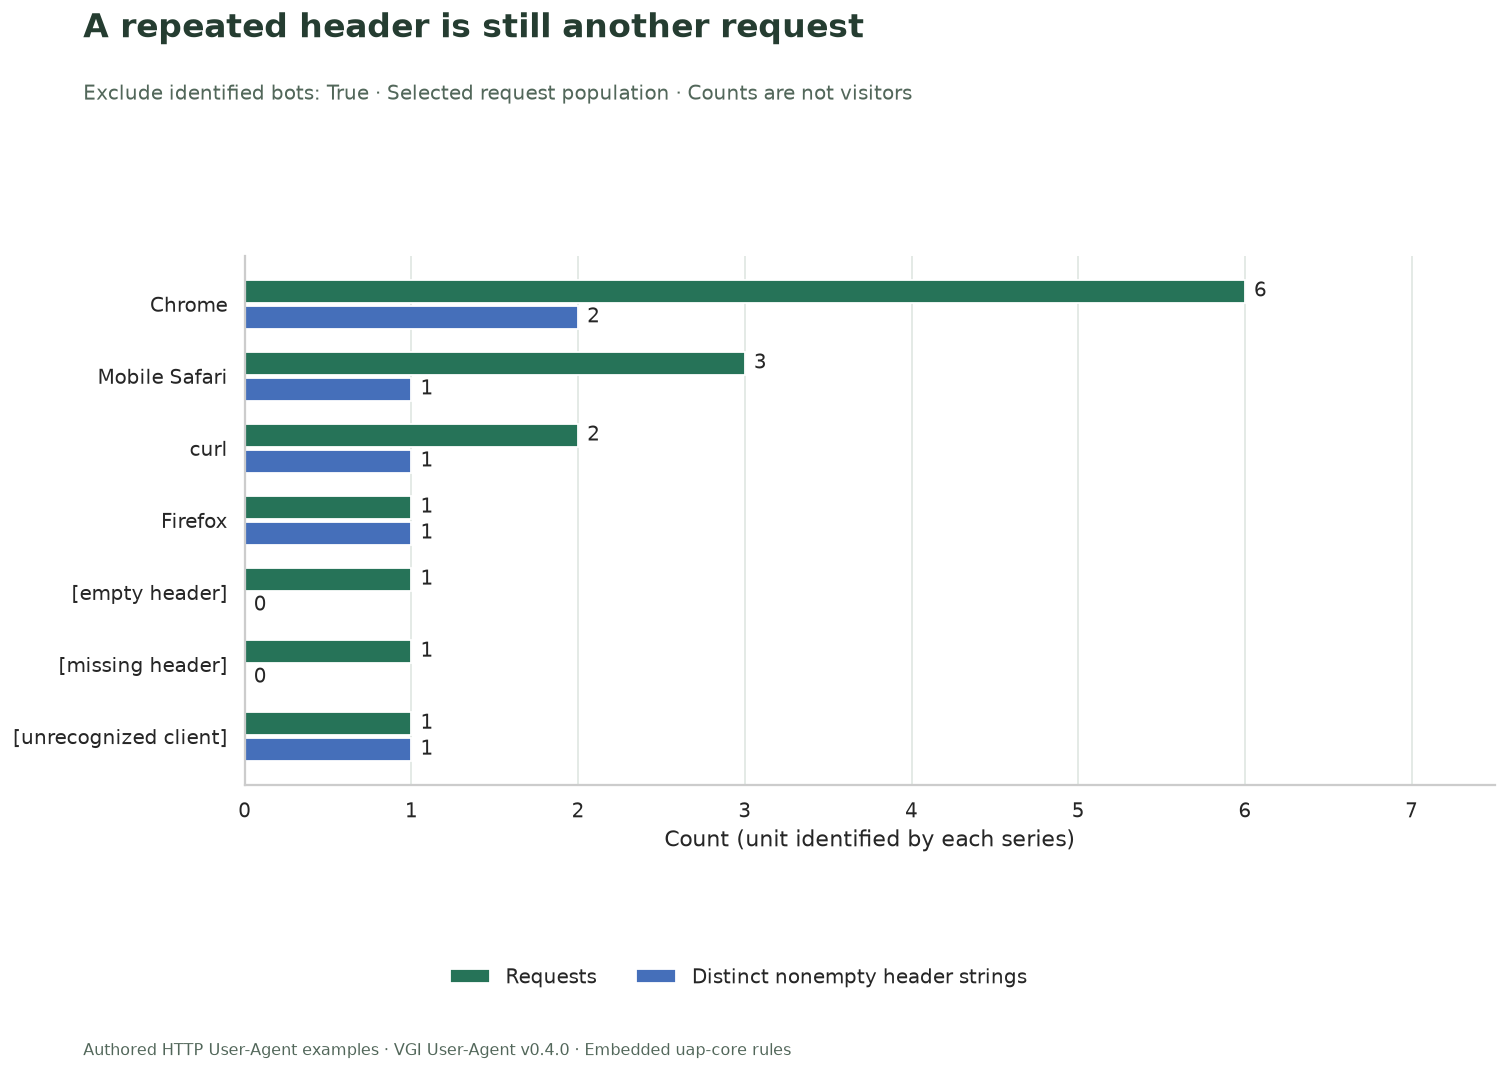

The selected population contains **15 requests** and **6 distinct nonempty strings**. Chrome's two version strings share one family; repeated uses still contribute separate requests. The family grouping is deterministic for this pinned regex database, not a durable identifier.

,browser_bucket,requests,distinct_nonempty_strings,selected_request_share_percent
0,Chrome,6,2,40.000000
1,Mobile Safari,3,1,20.000000
2,curl,2,1,13.333333
3,Firefox,1,1,6.666667
4,[empty header],1,0,6.666667
5,[missing header],1,0,6.666667
6,[unrecognized client],1,1,6.666667


In [11]:
fig, ax = plt.subplots(figsize=(12, 8.4))
y = np.arange(len(browser_counts))
for offset, column, color, label in [
    (-0.18, "requests", "#267358", "Requests"),
    (0.18, "distinct_nonempty_strings", "#456fba", "Distinct nonempty header strings"),
]:
    bars = ax.barh(y + offset, browser_counts[column], height=0.32, color=color, label=label)
    ax.bar_label(bars, padding=5, fontsize=11)
ax.set_yticks(y, browser_counts.browser_bucket)
ax.invert_yaxis()
ax.set_xlim(0, max(int(browser_counts.requests.max()), 1) * 1.25)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Count (unit identified by each series)")
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.07),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "A repeated header is still another request",
    f"Exclude identified bots: {EXCLUDE_IDENTIFIED_BOTS} · Selected request population · Counts are not visitors",
    "02_requests_and_strings.png",
    bottom=0.19,
)
prose(
    f"The selected population contains **{int(browser_counts.requests.sum())} requests** and "
    f"**{int(browser_counts.distinct_nonempty_strings.sum())} distinct nonempty strings**. "
    "Chrome's two version strings share one family; repeated uses still contribute separate requests. "
    "The family grouping is deterministic for this pinned regex database, not a durable identifier."
)
display(browser_counts)

## Keep field availability visible too

A recognized browser can lack an OS, device model or brand. These are counts of
requests with a returned field, not independent confirmations of the client. Retain
unknown fields instead of assigning a default device class or operating system.

In [12]:
%%sql
SELECT count(*) AS selected_requests,count(browser) AS browser_known,
 count(browser_version) AS browser_version_known,count(os) AS os_known,
 count(device) AS device_model_known,count(brand) AS brand_known,
 count(is_bot) AS bot_flag_available
FROM selected_requests;

,selected_requests,browser_known,browser_version_known,os_known,device_model_known,brand_known,bot_flag_available
0,15,12,12,10,3,3,14


## Verify row preservation, NULL semantics and counts

The checks establish that dictionary parsing did not drop or multiply requests,
selection keeps missing/empty states, and bot/device conventions remain explicit.
They do not assert that the parser proves a person's identity or the truth of a header.

In [13]:
%%sql checks <<
SELECT 'Authored repetition counts reproduce the request population' AS check_name,
 (SELECT count(*) FROM requests)=(SELECT sum(repetitions) FROM header_patterns) AS passed
UNION ALL SELECT 'Dictionary join preserves every request exactly once',
 (SELECT count(*) FROM parsed_requests)=(SELECT count(*) FROM requests)
 AND (SELECT count(DISTINCT request_id) FROM parsed_requests)=(SELECT count(*) FROM requests)
UNION ALL SELECT 'Dictionary retains NULL as its own key',
 (SELECT count(*) FROM parsed_headers)=(SELECT count(DISTINCT ua)+count(*) FILTER(WHERE ua IS NULL) FROM header_patterns)
UNION ALL SELECT 'All strings inside parser byte bound',
 NOT EXISTS(SELECT 1 FROM requests WHERE octet_length(encode(ua))>65536)
UNION ALL SELECT 'SQL NULL input is a NULL struct and flag',
 NOT EXISTS(SELECT 1 FROM parsed_requests WHERE ua IS NULL AND (parsed IS NOT NULL OR is_bot IS NOT NULL))
UNION ALL SELECT 'Empty input is an unrecognized struct with false bot flag',
 NOT EXISTS(SELECT 1 FROM parsed_requests WHERE ua='' AND (parsed IS NULL OR browser IS NOT NULL OR is_bot IS DISTINCT FROM false))
UNION ALL SELECT 'Spider device and brand suppressed',
 NOT EXISTS(SELECT 1 FROM parsed_requests WHERE is_bot AND (device IS NOT NULL OR brand IS NOT NULL))
UNION ALL SELECT 'Missing and empty headers survive selection',
 (SELECT count(*) FROM selected_requests WHERE ua IS NULL OR ua='')=(SELECT count(*) FROM requests WHERE ua IS NULL OR ua='')
UNION ALL SELECT 'Only explicit bot rows may be omitted',
 (SELECT count(*) FROM selected_requests)=(SELECT count(*) FROM request_audit WHERE NOT {{ EXCLUDE_IDENTIFIED_BOTS }} OR is_bot IS DISTINCT FROM true)
 AND NOT EXISTS(SELECT 1 FROM request_audit a ANTI JOIN selected_requests s USING(request_id) WHERE a.is_bot IS DISTINCT FROM true)
UNION ALL SELECT 'Naive predicate difference equals missing flags',
 (SELECT explicit_not_true_rows-naive_not_bot_rows FROM selection_audit)=(SELECT count(*) FROM request_audit WHERE is_bot IS NULL)
UNION ALL SELECT 'Known client fields never use Other sentinel',
 NOT EXISTS(SELECT 1 FROM parsed_requests WHERE browser='Other' OR os='Other' OR device='Other');

In [14]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
selected_count = con.execute("SELECT count(*) FROM selected_requests").fetchone()[0]
assert int(browser_counts.requests.sum()) == selected_count
assert abs(float(browser_counts.selected_request_share_percent.sum()) - 100.0) < 1e-9
prose(
    f"**{len(checks)} SQL checks plus request-count/share reconciliations passed.** Missing and unrecognized headers remain accounted for."
)

**11 SQL checks plus request-count/share reconciliations passed.** Missing and unrecognized headers remain accounted for.

## Experiment · include the identified bot signatures

Change only `EXCLUDE_IDENTIFIED_BOTS` from `True` to `False`, restart, and run all.
Predict which buckets appear in the second chart. Compare the selected denominator
and browser shares: unchanged request counts can have smaller shares in the larger
population. The full header-state chart and each parsed value should remain unchanged.

This changes the reporting scope; it does not verify additional visitors or correct
the parser's classification. Reset `EXCLUDE_IDENTIFIED_BOTS=True` for the saved default.

In [15]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)